# Rescaling NIRSpec contrast curves

In this notebook we will use the sensitivity analysis in Ruffio 2024 (https://doi.org/10.3847/1538-3881/ad5281) and demonstrate how to rescale the contrast curves to estimate NIRSpec sensitivity under different observing assumptions.

The first step is to load the data in `contrasts.npy` which is equivalent to the machine-readable data provided for Figure 14 in Ruffio 2024, and to instantiate variables the integration time and K-band magnitude of the host star HD 19467 which will serve as a reference.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

contrast_array = np.load('contrasts.npy')

HD19467_Tint = 1971 # seconds = 35 min
HD19467_Kmag = 5.4 # Vega magnitude

The following cell contains the used-specified inputs that need to be modified to customize the calculation:

`target_separation`: the estimated 1D separation of the companion

`myfilter`: one of `F356W`, `F444W`, `Lp`, `Mp`, the filter used to measure the companion-host flux ratio

`DeltaMag`: the difference in magnitude between the companion and host in the specified filter

`myTeff`: approximate effective temperature of the companion (sensitivity depends template shape / presence of certain molecules)

`star_Kmag`: the K-band magnitude of the host star

`Tint`: the planned exposure time (in seconds)

In [7]:
target_separation = 0.3 #arcsec

myfilter= 'Lp' #Choices of: F356W, F444W, Lp, Mp
DeltaMag = 9

myTeff = 1000 #Choices of: 500, 1000, 1500, 2000, 2500, 3000 (K)
star_Kmag = 7

Tint = 5*3600 #5 hours -> seconds

This cell transforms `DeltaMag` into a flux ratio, although you could specify this independently as welll.

In [8]:
target_host_flux_ratio = 10**(-(DeltaMag/2.5))

The `rescaling_factor` assumes that the sensitivity analysis reaches the photon noise floor, and uses the square root of the exposure times ratio in addition to the K-band magnitude ratio to adjust the expected sensitivity, so extrapolate with caution. In general it would also wise to also check that the local contrast Q > 1e-3 so as to not have observations be systematics-dominated.

In [10]:
rescaling_factor = np.sqrt(HD19467_Tint/Tint*10**((star_Kmag-HD19467_Kmag)/2.5))

The following cell matches the user-specified inputs to the array of tabulated values and rescales based on the assumptions above.

In [11]:
separations = contrast_array[1::,0].astype(float)/1000  #convert from mas to as
filters = contrast_array[1::,1::].astype(float)
labels = contrast_array[0,:].tolist()
column_id = labels.index('{0} - Teff = {1}K'.format(myfilter,myTeff))
scaled_5sig_contrast = filters[:, column_id]*rescaling_factor

The final results are plotted below.

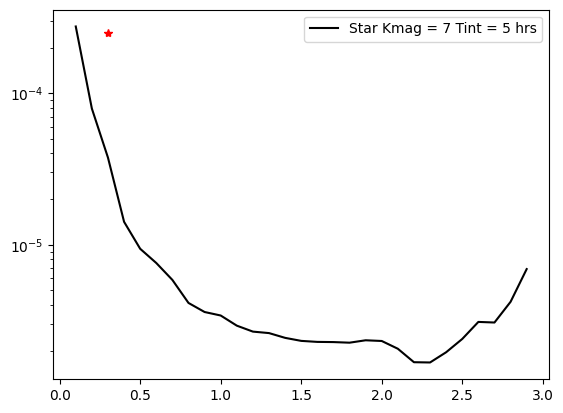

In [12]:
label = 'Star Kmag = {} '.format(star_Kmag)+'Tint = {} hrs'.format(Tint//3600)
plt.semilogy(separations,scaled_5sig_contrast,alpha=1,c='k',linestyle='-',label=label)
plt.plot(target_separation,target_host_flux_ratio,'r*')
plt.legend()

We can estimate the expected contrast by taking dividing of the target-host flux ratio with the expected achievable contrast and multiplying by five.

In [14]:
estimated_achievable_contrast = np.interp(target_separation,separations,scaled_5sig_contrast)
estimated_SNR = target_host_flux_ratio/estimated_achievable_contrast*5
estimated_SNR

33.457938592349926

However, these 1D curves ignore 2D detector issues, so one will also need to check the expected V3PA of the observation time to ensure that the companion does not land in the spectral trace that is saturated by starlight (example: https://github.com/jruffio/breads/blob/main/docs/source/jwst_tools/demo_planning_jwst_ifu_obs.ipynb). In gneral being close to the saturation in IFUX also increases the systematic noise, so the 1D approximation comes with caveats.